# Data-Driven Real-Time Variometer

**Data Challenge kickoff**

A variometer tells a glider pilot how fast the aircraft is climbing or sinking. To prevent it from reacting to mere changes in airspeed (e.g. pulling the stick back causes the altitude to increase and the airspeed to decrease), it is **total energy compensated**. Therefore, what we want is not the rate of change of altitude, but the rate of change of the aircraft's total energy.

Your task: from the sensor data of the last **30 seconds**, predict the current value of the target variometer. Your prediction has to be **causally**, i.e. without looking into the future, just as an instrument in the cockpit has to.

In this notebook we
1. load one training flight,
2. take a short look at the dataset (data exploration),
3. build a baseline without machine learning, by computing the classic total energy variometer from static pressure and dynamic pressure, and
4. evaluate it in the same way your submissions will be evaluated at the end of the data challenge.

## 1. Imports and data

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt


from scipy.signal import lfilter

plt.rcParams["figure.dpi"] = 100

The dataset consists of **10 flights**: 7 flights in the training set and 3 flights in the test set. All flights are stored as Parquet files and recorded at **100 Hz**. For the kickoff we use a single training flight.

In [ ]:
FLIGHT = "260606_085830"   # training flight (short, approx. 3 h)

df_one_flight = pd.read_parquet(f"Train-Data/{FLIGHT}.parquet")

print(f"{df_one_flight.shape[0]:,} rows x {df_one_flight.shape[1]} columns")
df_one_flight.head(50)

1,057,433 rows x 80 columns


,acceleration_x,acceleration_y,acceleration_z,rotation_x,rotation_y,rotation_z,magnetic_x,magnetic_y,magnetic_z,pitot,...,acceleration_down,magnetic_north,magnetic_east,magnetic_down,vario_pressure,speed_compensation_tas,vario_uncompensated,speed_compensation_ins,position_down,_t
0,-0.199880,0.183591,-9.319702,-0.008248,-0.000067,-0.004260,-0.372703,-0.291262,0.917939,-9.4698,...,-9.404062,0.418437,0.028939,0.903357,0.338355,-2.929688,-0.010898,-0.000656,-388.758026,0.00
1,-0.003842,-0.163639,-9.892988,0.037001,-0.009048,0.001689,-0.373732,-0.289801,0.918384,-2.6305,...,-9.975569,0.419062,0.028697,0.903565,0.332698,0.000000,-0.010696,-0.000639,-388.758026,0.01
2,-0.089596,-0.031451,-9.800178,-0.005090,-0.035550,0.004634,-0.371781,-0.293196,0.919974,0.0000,...,-9.884649,0.419407,0.028932,0.903869,0.328006,-20.507812,-0.010683,-0.000603,-388.758026,0.02
3,0.152816,0.805124,-9.849911,-0.001926,-0.013191,-0.001998,-0.372256,-0.288333,0.918445,1.0522,...,-9.948614,0.419413,0.028669,0.903699,0.325294,0.000000,-0.010269,-0.000228,-388.758026,0.03
4,0.047430,0.103221,-11.100044,-0.016432,0.023879,-0.006878,-0.370749,-0.290277,0.918520,-2.6305,...,-11.198133,0.419155,0.029350,0.903569,0.324198,-12.109375,-0.001667,-0.000212,-388.758026,0.04


## 2. Data exploration

### 2.1 Which columns are there?

The 80 columns can be roughly sorted into groups. Important for you: the columns of the **Vario** group are **not included** in the test data. These columns are reference values of the Larus variometer and must not be used as an input. The column `vario` is the target value of the supervised learning task.

In [32]:
column_groups = {
    "IMU (acceleration, rotation rate, magnetic field)":
        [c for c in df_one_flight.columns if c.startswith(("acceleration_", "rotation_", "magnetic_"))
         and c not in ("acceleration_north", "acceleration_east", "acceleration_down",
                       "magnetic_north", "magnetic_east", "magnetic_down", "magnetic_disturbance")],
    "Air data (pressure sensors, temperature)":
        ["pitot", "static_pressure", "temperature_pcb"],
    "GNSS (position, velocity, time, reception)":
        ["latitude", "longitude", "position_up", "position_down", "velocity_north", "velocity_east",
         "velocity_down", "speed_accuracy", "sat_count", "sat_fix_type", "geo_separation",
         "pos_dilution_of_precision", "relpos_north", "relpos_east", "relpos_down", "rel_heading",
         "year", "month", "day", "hour", "minute", "second", "nanoseconds"],
    "Derived by the onboard computer (airspeed, wind, attitude, ...)":
        ["ias", "tas", "speed_ground", "track_ground", "wind_north", "wind_east", "wind_down",
         "wind_average_north", "wind_average_east", "wind_average_down", "circle_mode",
         "q0", "q1", "q2", "q3", "roll_angle", "pitch_angle", "yaw_angle",
         "effective_acceleration_vertical", "turn_rate", "slip_angle", "apparent_pitch_angle",
         "g_load", "pressure_altitude", "air_density", "magnetic_disturbance",
         "acceleration_north", "acceleration_east", "acceleration_down",
         "magnetic_north", "magnetic_east", "magnetic_down"],
    "Vario (target + related quantities, NOT in the test set)":
        ["vario", "vario_average", "vario_pressure", "vario_uncompensated",
         "speed_compensation_tas", "speed_compensation_ins"],
    "Other":
        ["_t", "system_state", "voltage", "dummy_for_data_alignment"],
}

# Columns that are missing in the test set
VARIO_COLUMNS = column_groups["Vario (target + related quantities, NOT in the test set)"] + ["dummy_for_data_alignment"]

for group, cols in column_groups.items():
    print(f"{group} ({len(cols)}):\n   " + ", ".join(cols))

IMU (acceleration, rotation rate, magnetic field) (12):
   acceleration_x, acceleration_y, acceleration_z, rotation_x, rotation_y, rotation_z, magnetic_x, magnetic_y, magnetic_z, magnetic_ext_x, magnetic_ext_y, magnetic_ext_z
Air data (pressure sensors, temperature) (3):
   pitot, static_pressure, temperature_pcb
GNSS (position, velocity, time, reception) (23):
   latitude, longitude, position_up, position_down, velocity_north, velocity_east, velocity_down, speed_accuracy, sat_count, sat_fix_type, geo_separation, pos_dilution_of_precision, relpos_north, relpos_east, relpos_down, rel_heading, year, month, day, hour, minute, second, nanoseconds
Derived by the onboard computer (airspeed, wind, attitude, ...) (32):
   ias, tas, speed_ground, track_ground, wind_north, wind_east, wind_down, wind_average_north, wind_average_east, wind_average_down, circle_mode, q0, q1, q2, q3, roll_angle, pitch_angle, yaw_angle, effective_acceleration_vertical, turn_rate, slip_angle, apparent_pitch_angle, g_l

### 2.2 Time axis, missing values and value ranges

`_t` is the time in seconds since the start of the recording. We check the sampling rate, whether any
values are missing, and look at the value ranges of some important quantities.

In [33]:
dt = np.diff(df_one_flight["_t"])
print(f"Duration of the recording: {df_one_flight['_t'].iloc[-1] / 60:.1f} min")
print(f"Time step: median {np.median(dt) * 1000:.1f} ms  (min {dt.min() * 1000:.1f} ms, max {dt.max() * 1000:.1f} ms)")
print(f"Missing values (NaN) in the whole flight: {df_one_flight.isna().sum().sum()}")

Duration of the recording: 176.2 min
Time step: median 10.0 ms  (min 4.8 ms, max 22.2 ms)
Missing values (NaN) in the whole flight: 0


### 2.3 Flight path and overview of the flight

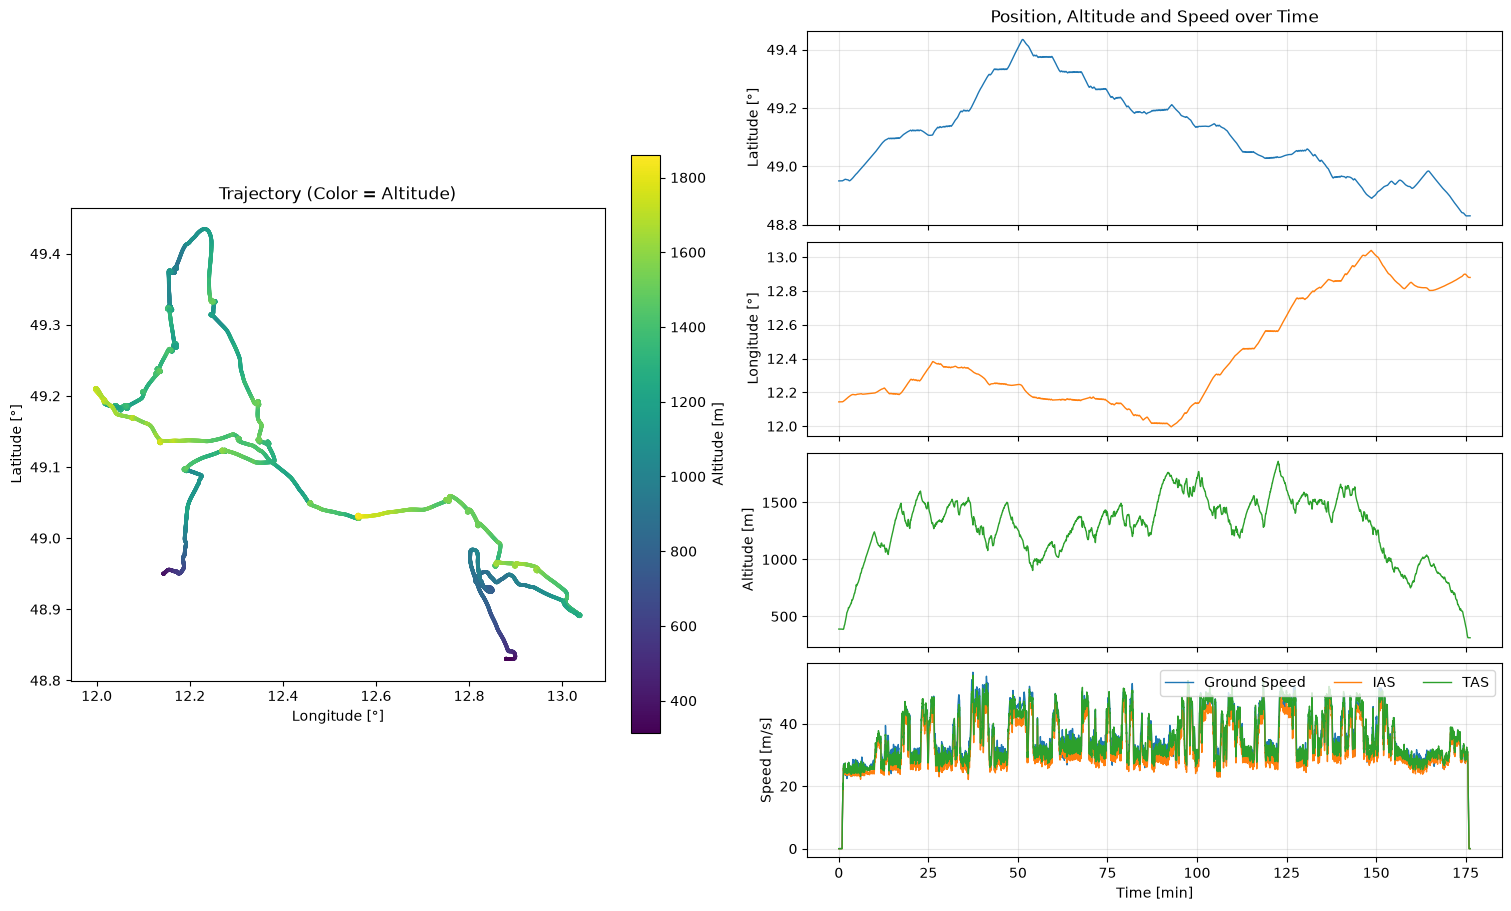

In [35]:
# Data set is sampled with 100 Hz -> plot every 100th point (1 Hz)
d = df_one_flight.iloc[::100]
t = d["_t"] / 60  # minutes since start

fig = plt.figure(figsize=(15, 9), constrained_layout=True)
gs = fig.add_gridspec(4, 2, width_ratios=[1, 1.3])

# Trajectory (top view), color = altitude
ax_map = fig.add_subplot(gs[:, 0])
sc = ax_map.scatter(d["longitude"], d["latitude"], c=d["position_up"], s=3, cmap="viridis")
ax_map.set_aspect(1 / np.cos(np.deg2rad(d["latitude"].mean())))
ax_map.set_xlabel("Longitude [°]")
ax_map.set_ylabel("Latitude [°]")
ax_map.set_title("Trajectory (Color = Altitude)")
fig.colorbar(sc, ax=ax_map, label="Altitude [m]", shrink=0.7)

# Time Series
ax = [fig.add_subplot(gs[i, 1]) for i in range(4)]
ax[0].plot(t, d["latitude"], lw=1, color="tab:blue")
ax[0].set_ylabel("Latitude [°]")
ax[0].set_title("Position, Altitude and Speed over Time")

ax[1].plot(t, d["longitude"], lw=1, color="tab:orange")
ax[1].set_ylabel("Longitude [°]")

ax[2].plot(t, d["position_up"], lw=1, color="tab:green")
ax[2].set_ylabel("Altitude [m]")

for col, label in [("speed_ground", "Ground Speed"), ("ias", "IAS"), ("tas", "TAS")]:
    ax[3].plot(t, d[col], lw=1, label=label)
ax[3].set_ylabel("Speed [m/s]")
ax[3].set_xlabel("Time [min]")
ax[3].legend(loc="upper right", ncol=3)

for a in ax:
    a.grid(alpha=0.3)
for a in ax[:-1]:
    a.sharex(ax[-1])
    a.tick_params(labelbottom=False)

plt.show()

### 2.4 Ground and flight phases

On the ground (before takeoff, after landing) the variometer is meaningless. In the test set, phases where the aircraft is on ground have been removed by only counting times with **IAS > 15 m/s** as flight. We will apply the same filter for our exemplary flight in this notebook.


In [36]:
MIN_IAS = 15.0  # [m/s]
airborne = df_one_flight["ias"] > MIN_IAS
print(f"Fraction airborne: {100 * airborne.mean():.1f} %  "
      f"({airborne.sum() / 100 / 60:.0f} of {len(df_one_flight) / 100 / 60:.0f} min)")

Fraction airborne: 99.1 %  (175 of 176 min)


### 2.5 The target `vario`

Positive values mean climbing, negative values sinking (in m/s). For comparison, the onboard computer also provides `vario_average`, a much more heavily averaged value.

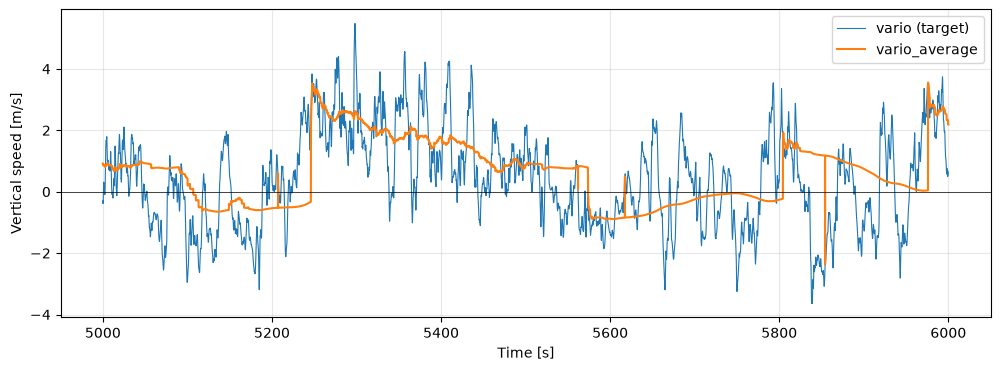

In [37]:
# variometer: section of 1000 s

t_start = 5000
t_end = 6000

plt.figure(figsize=(12, 4))
df_plot = df_one_flight[df_one_flight["_t"].between(t_start, t_end)]
plt.plot(df_plot["_t"], df_plot["vario"], lw=0.8, label="vario (target)")
plt.plot(df_plot["_t"], df_plot["vario_average"], label="vario_average")
plt.axhline(0, color="k", lw=0.5)
plt.xlabel("Time [s]")
plt.ylabel("Vertical speed [m/s]")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

## 3. Baseline without Machine Learning

### 3.1 Physics

The specific total energy of the aircraft per weight $m g$ is the **energy height**

$$
h_E = h + \frac{v^2}{2g}
$$

with altitude $h$ and true airspeed $v$ (TAS). The total-energy variometer (TEC) shows its time derivative:

$$
v_{vario} = \frac{\mathrm{d}h_E}{\mathrm{d}t}
$$


We compute the derivative using the two features `pressure_altitude` and `tas` from the data set.

### 3.2 Implementation

In [38]:
G = 9.80665       # gravitational acceleration [m/s^2]
DT = 0.01         # sampling interval [s] (100 Hz)

def baseline_vario(df):
    """TEC variometer [m/s] from the onboard computer values pressure_altitude and tas (causal)."""

    h = df["pressure_altitude"].to_numpy(dtype=float)   # altitude [m]
    v = df["tas"].to_numpy(dtype=float)                 # true airspeed [m/s]
    h_e = h + v**2 / (2 * G)                            # energy height [m]

    return np.r_[0.0, np.diff(h_e)] / DT

Now we apply the TE variometer to the whole flight and compare a section with the target. For
comparison we also show the unfiltered derivative and a variometer without airspeed compensation
(only $\mathrm{d}h/\mathrm{d}t$).

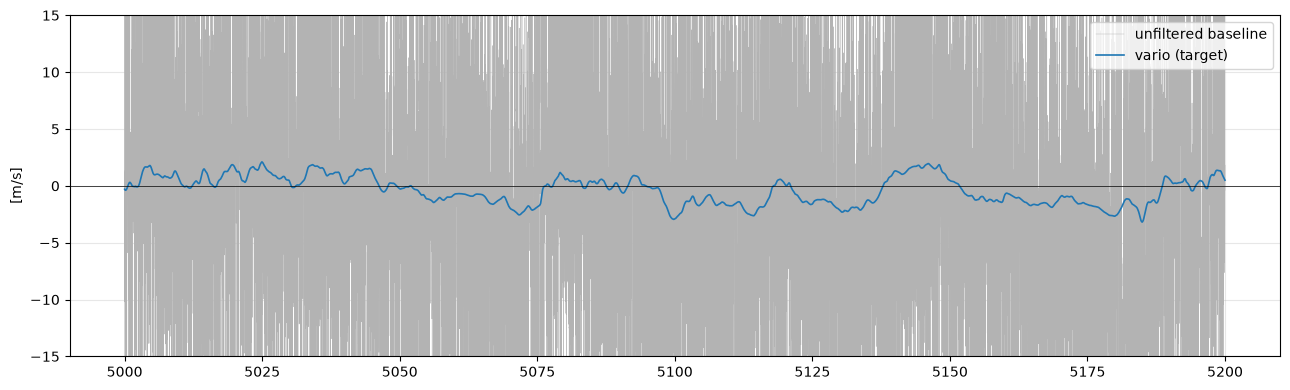

In [39]:
df_one_flight["baseline_vario"] = baseline_vario(df_one_flight)

t_start, t_end = 5000, 5200
m = df_one_flight["_t"].between(t_start, t_end).to_numpy()
t = df_one_flight["_t"].to_numpy()[m]

fig, ax = plt.subplots(figsize=(13, 4))
ax.plot(t, df_one_flight["baseline_vario"].to_numpy()[m], lw=0.3, color="0.7", label="unfiltered baseline")
ax.plot(t, df_one_flight["vario"].to_numpy()[m], lw=1.2, label="vario (target)")
ax.set_ylim(-15, 15)
ax.set_ylabel("[m/s]")
ax.axhline(0, color="k", lw=0.5)
ax.grid(alpha=0.3)
ax.legend(loc="upper right")
plt.tight_layout()
plt.show()


**Differentiation and filtering:** There is a lot of noise in the data, and numerical differentiation amplifies this noise strongly. We therefore smooth $h_E$ before differentiating, using a causal low-pass filter (an exponential moving average, EMA, with time constant $\tau$, applied twice in a row). 

$$ EMA[n] = a * x[n] + (1 - a) * EMA[n-1]) \quad\text{with } a=\frac{\mathrm{d}t}{\tau\,\mathrm{d}t} $$

Causal means: every output value depends only on current and past measurements. The price is a **delay**: the more we smooth, the later the variometer reacts.

In [40]:
def ema(x, tau, dt=DT):
    """Causal exponential moving average (first-order low-pass), time constant tau [s].
    y[n] = a * x[n] + (1 - a) * y[n-1]),  a = dt / (tau + dt). Initial value = first sample."""
    a = dt / (tau + dt)
    y, _ = lfilter([a], [1, a - 1], x, zi=[x[0] * (1 - a)])
    return y

def baseline_vario_filtered(df, tau):
    """Filtered TEC variometer [m/s] from the onboard computer values pressure_altitude and tas (causal)."""

    h = df["pressure_altitude"].to_numpy(dtype=float)   # altitude [m]
    v = df["tas"].to_numpy(dtype=float)                 # true airspeed [m/s]
    h_e = h + v**2 / (2 * G)                            # energy height [m]

    h_e_smooth = ema(ema(h_e, tau, dt=DT), tau, dt=DT)  # low-pass filter
    return np.r_[0.0, np.diff(h_e_smooth)] / DT

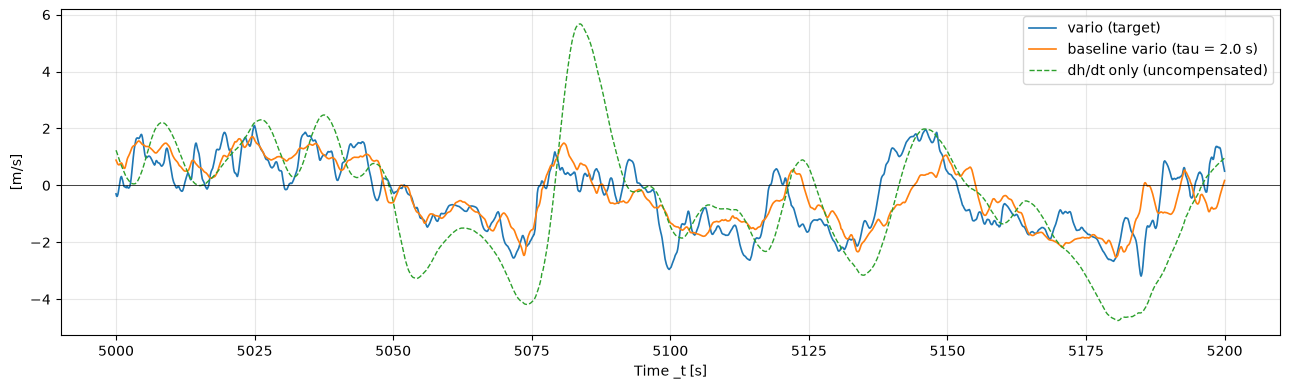

In [41]:
TAU = 2.0  # time constant of the low-pass filter [s]

df_one_flight["baseline_vario"] = baseline_vario_filtered(df_one_flight, tau=TAU)

t_start, t_end = 5000, 5200
m = df_one_flight["_t"].between(t_start, t_end).to_numpy()
t = df_one_flight["_t"].to_numpy()[m]

# for comparison
h = df_one_flight["pressure_altitude"].to_numpy(dtype=float)
dhdt = np.r_[0, np.diff(ema(ema(h, TAU), TAU))] / DT       # without airspeed compensation

fig, ax = plt.subplots(figsize=(13, 4))
ax.plot(t, df_one_flight["vario"].to_numpy()[m], lw=1.2, label="vario (target)")
ax.plot(t, df_one_flight["baseline_vario"].to_numpy()[m], lw=1.2, label=f"baseline vario (tau = {TAU} s)")
ax.plot(t, dhdt[m], lw=1, ls="--", label="dh/dt only (uncompensated)")
ax.set_xlabel("Time _t [s]")
ax.set_ylabel("[m/s]")
ax.axhline(0, color="k", lw=0.5)
ax.grid(alpha=0.3)
ax.legend(loc="upper right")
plt.tight_layout()
plt.show()

The filtered baseline variometer works much better. However, the smoothing introduces a time-dely making the predictions not really good compared to the target variometer.

## 4. Evaluation

### 4.1 Structure of the test set

The test flights are not handed out as a whole, but as individual **blocks of 30 s**, with gaps of 10 s between the blocks.

* Only complete blocks in which the aircraft is flying the entire time (IAS > 15 m/s) are used.
* For each block, **only one value** has to be predicted: the value of the target `vario` in the last row of the block. So you have exactly 30 s of history and no future.
* The columns of the Vario group are missing in the test data.
* Submissions are scored with the **RMSE** over all blocks:
  $\mathrm{RMSE} = \sqrt{\frac{1}{N}\sum_i (\hat y_i - y_i)^2}$

In this evaluation, we handle our flight in the same way as the test set flights.

In [42]:
BLOCK_S, GAP_S, FS = 30, 10, 100


def make_blocks(df, block_s=BLOCK_S, gap_s=GAP_S, fs=FS, min_ias=MIN_IAS):
    """Splits a flight into blocks like the test set (30 s block, 10 s gap).
    Returns a list of DataFrames (only complete blocks, airborne the whole time)."""
    t = df["_t"].to_numpy()
    rel = t - t[0]
    period = block_s + gap_s
    in_block = (rel % period) < block_s
    block_no = (rel // period).astype(int)
    blocks = []
    for _, chunk in df[in_block].groupby(block_no[in_block]):
        dt = np.diff(chunk["_t"].to_numpy())
        complete = abs(len(chunk) - block_s * fs) <= 1 and dt.max() <= 0.05 and dt.min() > 0
        if complete and chunk["ias"].min() > min_ias:
            blocks.append(chunk.reset_index(drop=True))
    return blocks


def rmse(y_pred, y_true):
    return float(np.sqrt(np.mean((np.asarray(y_pred) - np.asarray(y_true)) ** 2)))


blocks = make_blocks(df_one_flight.drop(columns="baseline_vario"))
# Target = vario in the last row
y_true = np.array([b["vario"].iloc[-1] for b in blocks])
blocks = [b.drop(columns=VARIO_COLUMNS) for b in blocks]
print(f"{len(blocks)} blocks of {BLOCK_S} s, input columns per block: {blocks[0].shape[1]}")

254 blocks of 30 s, input columns per block: 73


In [43]:
# Baseline: compute the TE variometer on each block separately, last value = prediction
y_pred_te = np.array([baseline_vario_filtered(b, tau=TAU)[-1] for b in blocks])

results = pd.Series({
    "Always predict 0 m/s": rmse(np.zeros_like(y_true), y_true),
    f"TE baseline (tau = {TAU} s)": rmse(y_pred_te, y_true),
}, name="RMSE [m/s]")
results.round(3).to_frame()

,RMSE [m/s]
Always predict 0 m/s,1.525
TE baseline (tau = 2.0 s),0.934


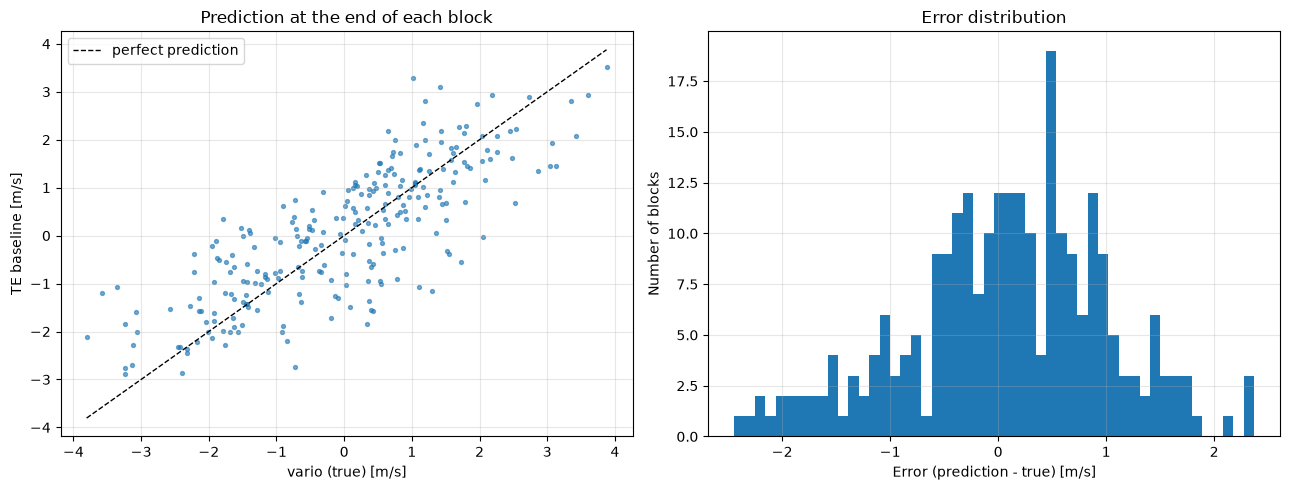

In [44]:
fig, ax = plt.subplots(1, 2, figsize=(13, 5))
ax[0].scatter(y_true, y_pred_te, s=8, alpha=0.6)
lim = [min(y_true.min(), y_pred_te.min()), max(y_true.max(), y_pred_te.max())]
ax[0].plot(lim, lim, "k--", lw=1, label="perfect prediction")
ax[0].set_xlabel("vario (true) [m/s]")
ax[0].set_ylabel("TE baseline [m/s]")
ax[0].set_title("Prediction at the end of each block")
ax[0].legend()
ax[1].hist(y_pred_te - y_true, bins=50)
ax[1].set_xlabel("Error (prediction - true) [m/s]")
ax[1].set_ylabel("Number of blocks")
ax[1].set_title("Error distribution")
for a in ax:
    a.grid(alpha=0.3)
plt.tight_layout()
plt.show()

### 4.2 Influence of the filter time constant

The time constant $\tau$ is the only parameter of the baseline. Small $\tau$: fast but noisy.
Large $\tau$: smooth but delayed. Where is the optimum?

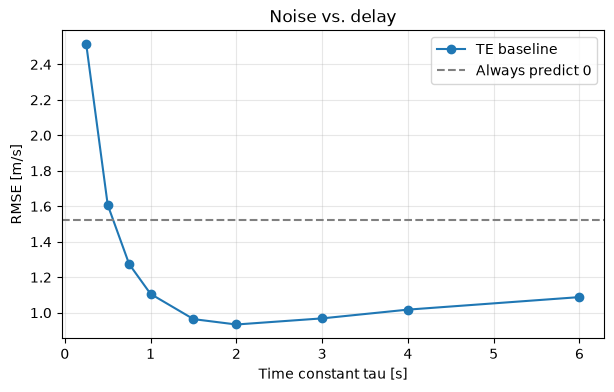

Best tau on this flight: 2 s with RMSE 0.934 m/s


In [45]:
taus = [0.25, 0.5, 0.75, 1, 1.5, 2, 3, 4, 6]
rmse_tau = [rmse([baseline_vario_filtered(b, tau=tau)[-1] for b in blocks], y_true) for tau in taus]

plt.figure(figsize=(7, 4))
plt.plot(taus, rmse_tau, marker="o", label="TE baseline")
plt.axhline(results["Always predict 0 m/s"], color="gray", ls="--", label="Always predict 0")
plt.xlabel("Time constant tau [s]")
plt.ylabel("RMSE [m/s]")
plt.title("Noise vs. delay")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

best = int(np.argmin(rmse_tau))
print(f"Best tau on this flight: {taus[best]} s with RMSE {rmse_tau[best]:.3f} m/s")

## 5. Start of the Data Challenge

The physical baseline is a starting point, but not a particularly good one. Measurement data are noisy and slow, and differentiation amplifies the noise. 

Here are some possible ideas for getting started with the task:

* **Use more sensors:** The data set contains a variety of measurements like accelerations, rotation rates, GNSS velocity, attitude angles ...
* **Features from the 30 s window:** Apply feature engineering to calculate useful features like filtered derivatives, mean values, trends, ...
* **Model selection:** Many possibilities from linear regression to gradient boosting or neural networks for time series, ...
* **Causality:** For each block, only the past up to the time of prediction is available.
* **Validation:** Split the training data into training and validation to evaluate your models.
